In [58]:
# Ethan Johnson
# Assignment 4

"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [59]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd

In [60]:
df = pd.read_csv('RAOBs_201903131200.txt', header=None, names=['station','lat','lon','z_500','udir','uspd'])

In [61]:
rho = 6371.0                   # km
phi0 = np.radians(60.0)        # standard latitude
lam0 = -100.0                  # reference longitude,
m = 1 / 15_000_000             # map scale

SCALE_TOP = 1 + np.sin(phi0)  


def r_from_pole_km(lat_deg):
    phi = np.radians(lat_deg)
    return rho * np.cos(phi) * SCALE_TOP / (1 + np.sin(phi))


def latlon_to_xy_cm(lat_deg, lon_deg):
    r_km = r_from_pole_km(lat_deg)
    r_map_cm = r_km * m * 100_000
    dlam = np.radians(lon_deg - lam0)
    x = r_map_cm * np.cos(dlam)
    y = r_map_cm * np.sin(dlam)
    return x, y


def xy_cm_to_latlon(x_cm, y_cm):
    r_map_cm = np.hypot(x_cm, y_cm)
    r_km = (r_map_cm / 100_000) / m
    ratio = r_km / (rho * SCALE_TOP)
    phi = np.pi / 2 - 2 * np.arctan(ratio)
    lat_deg = np.degrees(phi)
    dlam = np.arctan2(y_cm, x_cm)
    lon_deg = (lam0 + np.degrees(dlam) + 180) % 360 - 180
    return lat_deg, lon_deg


# 21 x 27 grid setup
NX, NY = 21, 27
DX = DY = 1.27                 
X0, Y0 = 25.0, -15.5           

x_vals = X0 + np.arange(NX) * DX
y_vals = Y0 + np.arange(NY) * DY

gyy, gxx = np.meshgrid(y_vals, x_vals)

grid_lat = np.empty((NX, NY))
grid_lon = np.empty((NX, NY))
for i, x in enumerate(x_vals):
    for j, y in enumerate(y_vals):
        lat, lon = xy_cm_to_latlon(x, y)
        grid_lat[i, j] = lat
        grid_lon[i, j] = lon

In [62]:
### convert obs lat/long to x,y ###
obs_x, obs_y = latlon_to_xy_cm(df["lat"].values, df["lon"].values)
obs_z = df['z_500'].values
n_obs = len(obs_x)

df['x_cm'], df['y_cm'] = latlon_to_xy_cm(df['lat'].values, df['lon'].values)
x_cm, y_cm = np.meshgrid(x_vals, y_vals, indexing='ij')

In [63]:
xg = X0 + DX * np.arange(NX)
yg = Y0 + DX * np.arange(NY)
XG, YG = np.meshgrid(xg, yg)

KD = 10.8844524
RE = 12.7775892


def barnes_analysis(ax, ay, ox, oy, val, kd=KD, re=RE):
    d = np.sqrt((ox - ax)**2 + (oy - ay)**2)
    w = np.where(d <= re, np.exp(-d**2 / kd), 0.0)
    sum_w = w.sum()
    if sum_w == 0:
        return np.nan
    return (w * val).sum() / sum_w

def bilinear_pts(px, py, x_vals, y_vals, field):
    dx = x_vals[1] - x_vals[0]
    dy = y_vals[1] - y_vals[0]
    inside = (px >= x_vals[0]) & (px <= x_vals[-1]) & (py >= y_vals[0]) & (py <= y_vals[-1])
    out = np.full(px.shape, np.nan)
    i = np.clip(np.floor((px[inside] - x_vals[0]) / dx).astype(int), 0, len(x_vals) - 2)
    j = np.clip(np.floor((py[inside] - y_vals[0]) / dy).astype(int), 0, len(y_vals) - 2)
    # fractional position within the cell
    tx = (px[inside] - x_vals[i]) / dx
    ty = (py[inside] - y_vals[j]) / dy
    f00 = field[i, j]
    f10 = field[i+1, j]
    f01 = field[i, j+1]
    f11 = field[i+1, j+1]
    out[inside] = (f00*(1 - tx)*(1 - ty) + f10*tx*(1 - ty) + f01*(1 - tx)*ty + f11*tx*ty)
    return out


def grid_st(ox, oy, x_vals, y_vals, field):
    vals = bilinear_pts(obs_x, obs_y, x_vals, y_vals, field)
    outside = ~((obs_x >= x_vals[0]) & (obs_x <= x_vals[-1]) &
                (obs_y >= y_vals[0]) & (obs_y <= y_vals[-1]))
    if outside.any():
        gx, gy, gf = gxx.ravel(), gyy.ravel(), field.ravel()
        ok = ~np.isnan(gf)
        for k in np.where(outside)[0]:
            vals[k] = barnes_analysis(obs_x[k], obs_y[k], gx[ok], gy[ok], gf[ok])
    return vals

fB_grid = np.full((NX, NY), np.nan)
for i in range(NX):
    for j in range(NY):
        fB_grid[i, j] = barnes_analysis(x_vals[i], y_vals[j], obs_x, obs_y, obs_z)

fB_stn = grid_st(obs_x, obs_y, x_vals, y_vals, fB_grid)

In [64]:
# schlatter correlation
S40 = (1 + np.sin(np.radians(60))) / (1 + np.sin(np.radians(40)))
km_per_cm = 1.0 / (m * S40) / 1e5 / 1000.0
B_CM = 1.24 * km_per_cm**2

def schlatter(d):
    rho = 0.95 * np.exp(-B_CM * d**2)
    rho = np.where(d < 10^-6, 1.0, rho) # 1 when d is less than 10^-8 m (this value is in cm)
    return rho


def SOA(N, fB_grid, fB_stn):
    valid = np.isfinite(fB_stn)
    sx, sy = obs_x[valid], obs_y[valid]
    innov_all = val[valid] - fB_stn[valid]

    gx, gy = gxx.ravel(), gyy.ravel()
    dss = np.hypot(sx[:, None] - sx[None, :], sy[:, None] - sy[None, :])
    P_full = schlatter(dss)

    dgs = np.hypot(gx[:, None] - sx[None, :], gy[:, None] - sy[None, :])
    idx = np.argsort(dgs, axis=1)[:, :N]

    P = P_full[idx[:, :, None], idx[:, None, :]]
    rho_i = schlatter(np.take_along_axis(dgs, idx, axis=1))
    w = np.linalg.solve(P, rho_i[..., None])[..., 0]

    incr = np.sum(w * innov_all[idx], axis=1).reshape(NX, NY)
    return fB_grid + incr, incr
    
results = {}
for N in (2, 4, 10):
    fA_grid, incr = SOA(N, fB_grid, fB_stn)
    fA_st = grid_st(obs_x, obs_y, x_vals, y_vals, fA_grid)
    diff = fA_st - val               # analysis minus observation
    rms = np.sqrt(np.nanmean(diff**2))
    results[N] = dict(fA=fA_grid, incr=incr, fA_stn=fA_st, diff=diff, rms=rms)
    print(f"N = {N:2d}   RMS = {rms:.3f}")

N =  2   RMS = 62.339
N =  4   RMS = 61.089
N = 10   RMS = 63.642


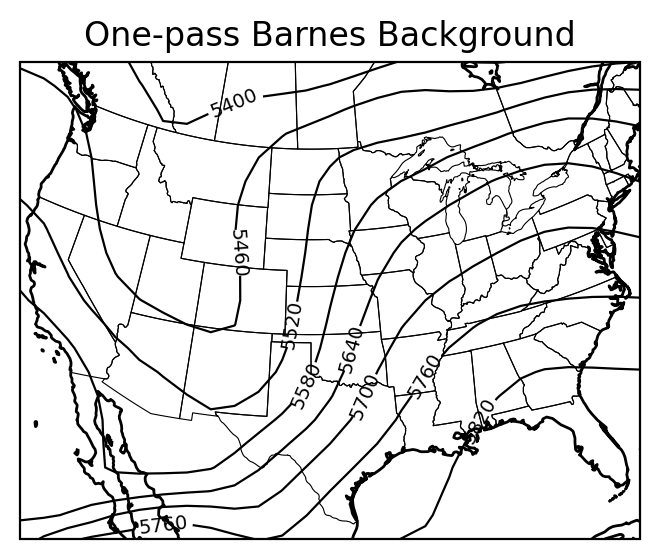

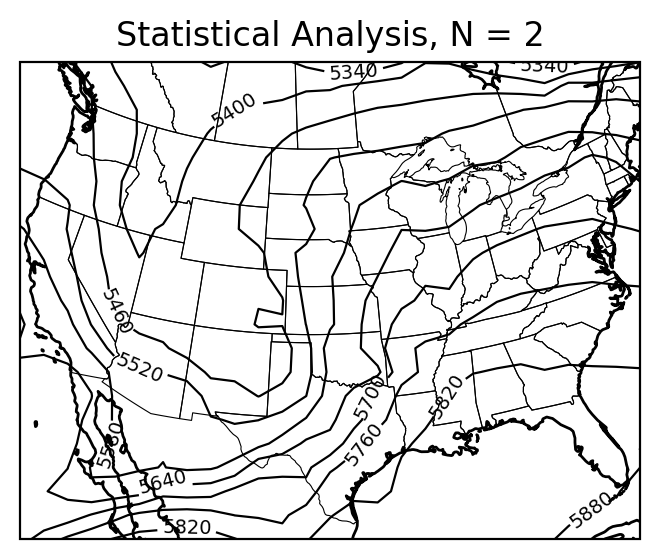

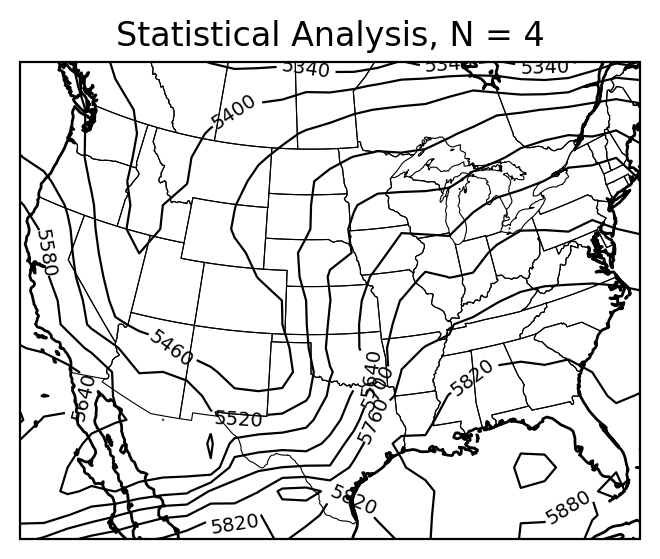

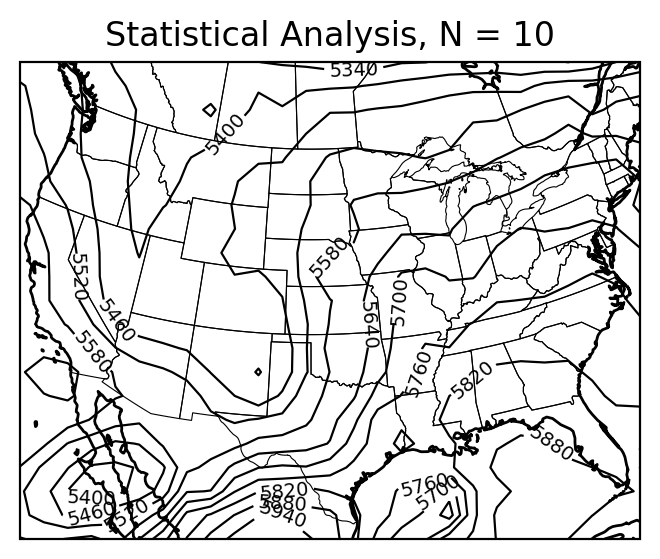

In [68]:
XG, YG = np.meshgrid(xg, yg)
Ns = (2, 4, 10)

allfA = np.concatenate([results[2]["fA"].ravel(), results[4]["fA"].ravel(), results[10]["fA"].ravel(), fB_grid.ravel()])
allfA = allfA[~np.isnan(allfA)]
CI = 60                                    # contour interval
lo = np.floor(allfA.min() / CI) * CI
hi = np.ceil(allfA.max() / CI) * CI
levels_fA = np.arange(lo, hi + CI, CI)

allinc = np.concatenate([results[2]["incr"].ravel(), results[4]["incr"].ravel(), results[10]["incr"].ravel()])
amax = np.nanmax(np.abs(allinc))
inc_levels = np.arange(-150, 151, 10)

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho*1000, semiminor_axis=rho*1000)
proj = ccrs.Stereographic(central_longitude=lam0, central_latitude=90,
                          true_scale_latitude=60.0, globe=globe)


map_x = gyy / 100 / m
map_y = -gxx / 100 / m

hgt_levels = np.arange(4800, 6000, 60)

# background
fig = plt.figure(figsize=(4, 4), dpi=200)
ax1 = fig.add_subplot(111, projection=proj)
ax1.add_feature(cfeature.STATES, linewidth=0.4)
ax1.add_feature(cfeature.COASTLINE)
cs1 = ax1.contour(map_x, map_y, fB_grid, levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax1.clabel(cs1, fmt='%d', fontsize=7)
ax1.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax1.set_title('One-pass Barnes Background')
#plt.savefig('background.png', dpi=300, bbox_inches='tight')
plt.show()


# analysis N = 2
fig = plt.figure(figsize=(4, 4), dpi=200)
ax2 = fig.add_subplot(111, projection=proj)
ax2.add_feature(cfeature.STATES, linewidth=0.4)
ax2.add_feature(cfeature.COASTLINE)
cs2 = ax2.contour(map_x, map_y, results[2]["fA"], levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax2.clabel(cs2, fmt='%d', fontsize=7)
ax2.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax2.set_title('Statistical Analysis, N = 2')
#plt.savefig('analysis_N02.png', dpi=300, bbox_inches='tight')
plt.show()


# analysis N = 4
fig = plt.figure(figsize=(4, 4), dpi=200)
ax3 = fig.add_subplot(111, projection=proj)
ax3.add_feature(cfeature.STATES, linewidth=0.4)
ax3.add_feature(cfeature.COASTLINE)
cs3 = ax3.contour(map_x, map_y, results[4]["fA"], levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax3.clabel(cs3, fmt='%d', fontsize=7)
ax3.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax3.set_title('Statistical Analysis, N = 4')
#plt.savefig('analysis_N04.png', dpi=300, bbox_inches='tight')
plt.show()


# analysis N = 10
fig = plt.figure(figsize=(4, 4), dpi=200)
ax4 = fig.add_subplot(111, projection=proj)
ax4.add_feature(cfeature.STATES, linewidth=0.4)
ax4.add_feature(cfeature.COASTLINE)
cs4 = ax4.contour(map_x, map_y, results[10]["fA"], levels=hgt_levels, colors='k', linewidths=0.8, transform=proj)
ax4.clabel(cs4, fmt='%d', fontsize=7)
ax4.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax4.set_title('Statistical Analysis, N = 10')
#plt.savefig('analysis_N10.png', dpi=300, bbox_inches='tight')
plt.show()

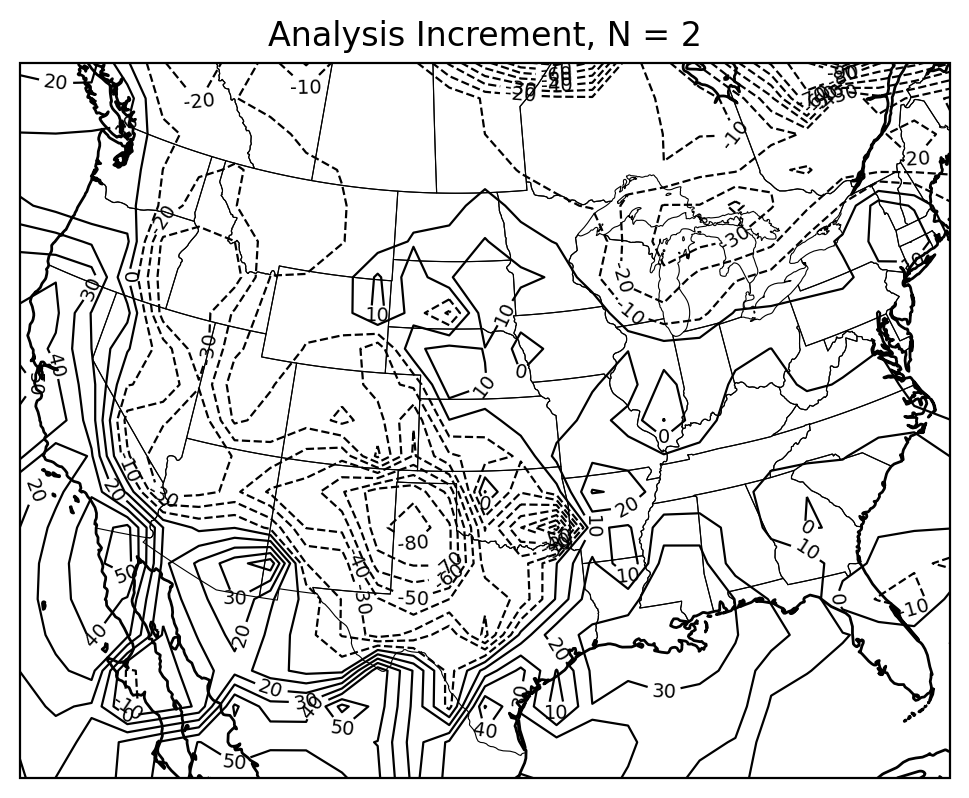

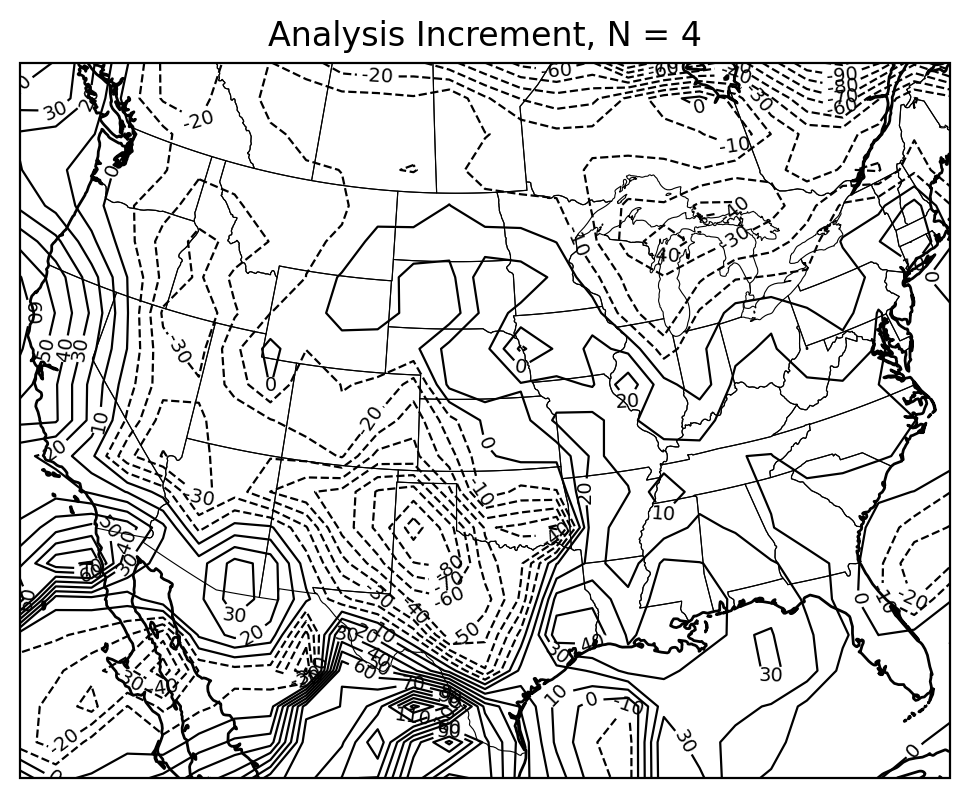

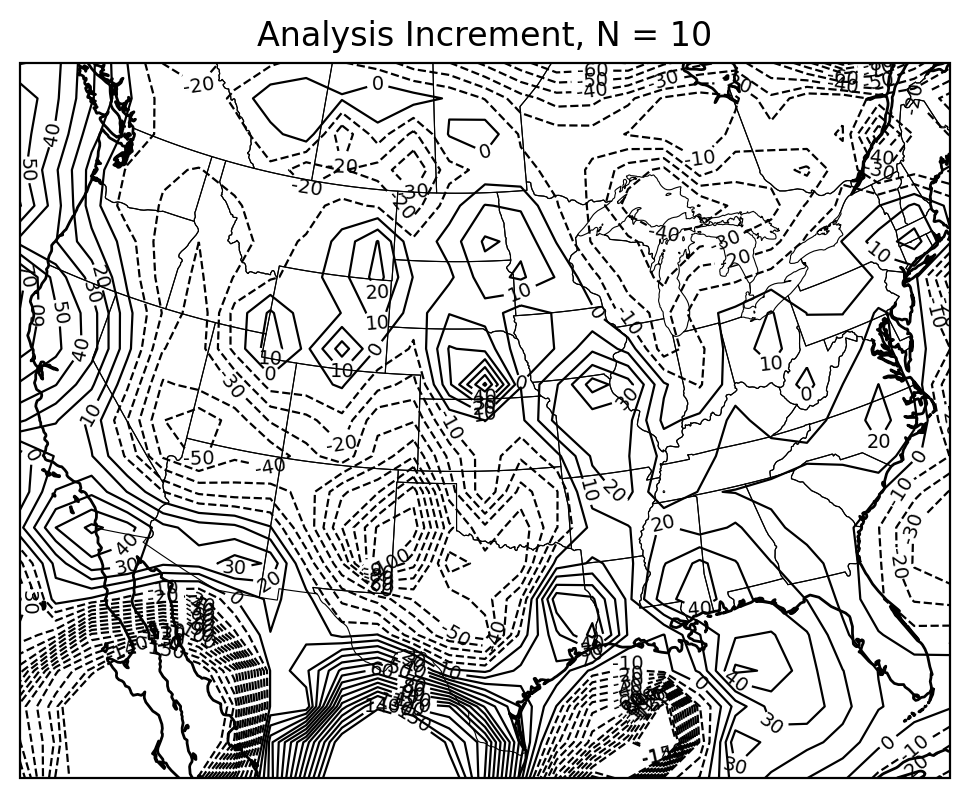

In [69]:
# increment N = 2
fig = plt.figure(figsize=(6, 6), dpi=200)
ax5 = fig.add_subplot(111, projection=proj)
ax5.add_feature(cfeature.STATES, linewidth=0.4)
ax5.add_feature(cfeature.COASTLINE)
cs5 = ax5.contour(map_x, map_y, results[2]["incr"], levels=inc_levels, colors='k', linewidths=0.8, transform=proj)
ax5.clabel(cs5, fmt='%d', fontsize=7)
ax5.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax5.set_title('Analysis Increment, N = 2')
#plt.savefig('increment_N02.png', dpi=300, bbox_inches='tight')
plt.show()


# increment N = 4
fig = plt.figure(figsize=(6, 6), dpi=200)
ax6 = fig.add_subplot(111, projection=proj)
ax6.add_feature(cfeature.STATES, linewidth=0.4)
ax6.add_feature(cfeature.COASTLINE)
cs6 = ax6.contour(map_x, map_y, results[4]["incr"], levels=inc_levels, colors='k', linewidths=0.8, transform=proj)
ax6.clabel(cs6, fmt='%d', fontsize=7)
ax6.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax6.set_title('Analysis Increment, N = 4')
#plt.savefig('increment_N04.png', dpi=300, bbox_inches='tight')
plt.show()


# increment N = 10
fig = plt.figure(figsize=(6, 6), dpi=200)
ax7 = fig.add_subplot(111, projection=proj)
ax7.add_feature(cfeature.STATES, linewidth=0.4)
ax7.add_feature(cfeature.COASTLINE)
cs7 = ax7.contour(map_x, map_y, results[10]["incr"], levels=inc_levels, colors='k', linewidths=0.8, transform=proj)
ax7.clabel(cs7, fmt='%d', fontsize=7)
ax7.set_extent([map_x.min(), map_x.max(), map_y.min(), map_y.max()], crs=proj)
ax7.set_title('Analysis Increment, N = 10')
#plt.savefig('increment_N10.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# np.savetxt("analysis_N02.txt", results[2]["fA"].T, fmt="%.4f")
# np.savetxt("analysis_N04.txt", results[4]["fA"].T, fmt="%.4f")
# np.savetxt("analysis_N10.txt", results[10]["fA"].T, fmt="%.4f")

# np.savetxt("increment_N02.txt", results[2]["incr"].T, fmt="%.4f")
# np.savetxt("increment_N04.txt", results[4]["incr"].T, fmt="%.4f")
# np.savetxt("increment_N10.txt", results[10]["incr"].T, fmt="%.4f")

# hdr = "x_cm y_cm obs analysis analysis_minus_obs"
# np.savetxt("station_diff_N02.txt",
#            np.column_stack([ox, oy, val, results[2]["fA_stn"], results[2]["diff"]]),
#            fmt="%.4f", header=hdr)
# np.savetxt("station_diff_N04.txt",
#            np.column_stack([ox, oy, val, results[4]["fA_stn"], results[4]["diff"]]),
#            fmt="%.4f", header=hdr)
# np.savetxt("station_diff_N10.txt",
#            np.column_stack([ox, oy, val, results[10]["fA_stn"], results[10]["diff"]]),
#            fmt="%.4f", header=hdr)

# with open("rms.txt", "w") as f:
#     f.write(f"N =  2  RMS = {results[2]['rms']:.4f}\n")
#     f.write(f"N =  4  RMS = {results[4]['rms']:.4f}\n")
#     f.write(f"N = 10  RMS = {results[10]['rms']:.4f}\n")

# plt.show()

In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.

The N=2 analysis map shows generally a large trough over the western half of the U.S. and a ridge over the eastern half. The 540 dam contour dips 
down into Idaho and northeastern Nevada, but the pointed nadir seems a bit unrealistic and is probably a product of the analysis rather than a real 
atmospheric feature. A coulpe of the contours have kinks in them that also seem unrealistic, like the 546 dam contour through Colorado, but some 
features like the three contours that are kinked from eastern Oklahoma through western Arkansas may be noise, but could also be a real feature, like a 
shortwave trough. The N=4 analysis map shows the same general trend, but is a bit smoother than the previous analysis map. The weird point in the 
540 dam contour is still there, but some of the other oddities are more smoothed out now. The shortwave-like feature over OK/AR is still there, but 
less noticable. The max in geopotential heights over the gulf is more pronounced with a closed feature over the eastern gulf. The N=10 analysis map 
still has the same trough-ridge structure, and some of the same features as the last, but has more kinks in the contours than the last analysis map. 
The weird feature over southern Idaho and Nevada is reduced to just a point which is unrealistic. The shortwave feature over OK and AR is almost 
completely smoothed out now. There are a few weird maxima and minima near the southern bounds of the analysis map. These could be realistic if they 
represent centers of low pressure. My first though was tropical systems, but this takes place in March, so probably not.

The increment maps usually show negative values over regions of minima in geopotential height and positive valurs over regions of higher heights.
The differences increase as N increases. The incrememt map for N=10 has large magnitude differences along the southern border of the analysis map
where it showed local maxima and minima in geopotential height. The nadir of the trough over Texas and New Mexico has the largest difference over
the continental United States. The analysis maps are generally in close agreement regarding the ridge over the eastern U.S. where the increment maps 
are pretty close to zero for each one.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    
The contoured analyses for this assignment tend to have more kinks in them than the previous analysis methods. The N=2 map has the most kinks and 
seemingly unrealistic features, and the contours smooth out a bit for the N=4 map, and just a little more smooth for the N=10 map. The more stations 
taken into consideration for an analysis means averaging out across a larger area, so the data will be smoother with more and more stations included.
This means less noise makes it through the analysis, and thus a smoother analysis.

The increment maps are all generally noisy, but the N=2 map is the least messy, leaving the N=10 map the most messy. The increments seem to increase
as you increase the number of stations. The increment gradients also become more extreme as N increases. The analyses seem to handle zonal patterns
in geopotential height pretty well as the eastern U.S. stays pretty close to zero for the increment maps across all three values of N. The increment 
contours are smoother for the N=10 map than the previuos two increment maps for the same reason the N=10 analysis mas was the smoothest.

3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?

    Increasing the number of points considered in analysis takes information from stations that are further and further away from the grid point.
    This is a good thing to a certain point. You want more stations to be incldued in analysis as you can average out error from nearby stations 
    if one nearby observation is particularly bad, but eventually you begin to include stations so far away there really shouldn't be any correlation 
    considered between the grid point and that station. A station in central Michigan probably should be given much if any weight for an analysis point
    in southern California. 
    
'''